# Aim 2 simulation, version 2: full well signature, paracrine signalling, composition

The first simulator (`aim2_model_simulation.ipynb`) used a low-rank well effect, the same assumption as the first prototype, so the prototype matched the oracle there. Real data then showed that the well effect is **not** low rank. This simulator matches what the data showed and adds the biology that the internal-control model cannot separate from a well effect:

| Ingredient | What it does |
|---|---|
| Full well signature | every well has its own value per gene (not a few factors); part of it is identical on every donor plate (row, column, well-specific), part is donor-specific |
| Paracrine signalling (`paracrine`) | when the source cell type (monocyte-like) responds, a secondary program reaches the other cell types of the well; it is biological but shared by the well |
| Composition (`composition`) | wells where most cell types respond get an extra shift in every cell type (for example, cell death) |

**Estimand**: the direct (cell-autonomous) response. The paracrine and composition parts are biological but are, by design, removed by the internal-control model; `paracrine_kept` measures how much of the paracrine signal of receiving cell types survives.

**Methods**: naive, row/col, RUVg, low-rank prototype, signature (the model used on real data), **signature, two-part** (new: the part of a well's signature shared by all donors is averaged over donors before it is removed, which makes it much less noisy), and the oracle (true technical well effect removed). Responders for low-rank and both signature models come from the low-rank caller, as on real data.

All random steps use fixed seeds; every step prints its run time. Outputs: `results/cache/aim2_model_simulation_v2/`.

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="Degrees of freedom")
warnings.filterwarnings("ignore", message="All-NaN slice")

OUT_DIR = "results/cache/aim2_model_simulation_v2"
os.makedirs(OUT_DIR, exist_ok=True)
SEEDS = [100, 101, 102, 103, 104]
PARACRINE_GRID = [0.0, 0.25, 0.5, 1.0]
SHARED_GRID = [0.2, 0.4, 0.6, 0.8]
COMPOSITION_GRID = [0.0, 0.5, 1.0]
T_START = time.time()

ROWS = "ABCDEFGH"
WELLS = [r + str(c) for r in ROWS for c in range(1, 13)]
PBS = ["H7", "H8", "H9", "H10", "H11", "H12"]
ROW = np.array([ROWS.index(w[0]) for w in WELLS])
COL = np.array([int(w[1:]) - 1 for w in WELLS])

## 1. Simulator

In [2]:
def simulate2(seed=0, D=12, C=6, G=500, p_resp=0.3, frac_inert=0.15, shared_frac=0.4,
              well_sd=0.25, noise_sd=0.15, resp_size=0.5, resp_gene_frac=0.2,
              paracrine=0.0, source=3, composition=0.0, row_h=1.0):
    """Full-rank well signature, optional paracrine signalling and composition shift.
    Truth: tau_direct (the estimand) and tau_total (direct + paracrine + composition)."""
    rng = np.random.default_rng(seed)
    K = len(WELLS)
    is_pbs = np.isin(WELLS, PBS)
    # technical well signature: one value per gene, part repeated on every donor plate
    row_eff = rng.normal(0, 0.5, (8, G)); row_eff[7] += row_h * rng.normal(0, 1, G)
    col_eff = rng.normal(0, 0.3, (12, G))
    spatial = row_eff[ROW] + col_eff[COL] + rng.normal(0, 0.7, (K, G))
    s = spatial[None] + rng.normal(0, 0.7, (D, K, G))
    b = rng.uniform(0.5, 1.5, (C, 1)) * (1 + 0.3 * rng.normal(0, 1, (C, G)))
    W = s[:, :, None, :] * b[None, None]
    W *= well_sd / W.std()
    W_un = rng.normal(0, well_sd * np.sqrt((1 - shared_frac) / shared_frac), (D, K, C, G))
    # direct responses
    resp = np.zeros((K, C), bool)
    active = (~is_pbs) & (rng.random(K) > frac_inert)
    resp[active] = rng.random((active.sum(), C)) < p_resp
    tau = np.zeros((K, C, G))
    for k in np.where(resp.any(1))[0]:
        prog = (rng.random(G) < resp_gene_frac) * rng.normal(0, 1, G)
        for c in np.where(resp[k])[0]:
            tau[k, c] = resp_size * rng.uniform(0.5, 1.5) * prog * (1 + 0.3 * rng.normal(0, 1, G))
    # paracrine: if the source cell type responds, a secondary program reaches every cell type of the well
    bio_shared = np.zeros((K, C, G))
    if paracrine > 0:
        for k in np.where(resp[:, source])[0]:
            sec = (rng.random(G) < resp_gene_frac) * rng.normal(0, 1, G)
            sec *= paracrine * np.linalg.norm(tau[k, source]) / (np.linalg.norm(sec) + 1e-9)
            bio_shared[k] += sec[None] * rng.uniform(0.5, 1.5, (C, 1))
            bio_shared[k, source] = 0
    # composition: wells where most cell types respond shift every cell type (for example, cell death)
    if composition > 0:
        comp = rng.normal(0, 1, G); comp /= np.linalg.norm(comp)
        for k in np.where(resp.mean(1) >= 0.5)[0]:
            bio_shared[k] += composition * resp_size * np.sqrt(G * resp_gene_frac) * comp[None]
    mu = rng.normal(0, 1, (1, 1, C, G)) + rng.normal(0, 0.3, (D, 1, C, G))
    Y = mu + tau[None] + bio_shared[None] + W + W_un + rng.normal(0, noise_sd, (D, K, C, G))
    return dict(Y=Y.astype(np.float32), W=W.astype(np.float32), tau=tau, tau_total=tau + bio_shared,
                resp=resp, recv=(np.abs(bio_shared).sum(-1) > 0) & ~resp, is_pbs=is_pbs,
                inert=(~is_pbs) & ~resp.any(1))

## 2. Methods
`m_signature` is the model used on real data; `m_signature2` adds the donor-averaged part.

In [3]:
# ------------------------- methods -------------------------
def m_naive(Y, **kw):
    return Y


def m_rowcol(Y, **kw):
    Y1 = Y.copy()
    for r in range(8):
        Y1[:, ROW == r] -= Y[:, ROW == r].mean(1, keepdims=True)
    Y2 = Y1.copy()
    for c in range(12):
        Y2[:, COL == c] -= Y1[:, COL == c].mean(1, keepdims=True)
    return Y2


def m_ruvg(Y, R=3, ctrl_frac=0.1, **kw):
    D, K, C, G = Y.shape
    Y1 = np.empty_like(Y)
    for c in range(C):
        X = (Y[:, :, c] - Y[:, :, c].mean(1, keepdims=True)).reshape(D * K, G)
        ctrl = np.argsort(X.var(0))[: int(ctrl_frac * G)]
        U = np.linalg.svd(X[:, ctrl], full_matrices=False)[0][:, :R]
        Y1[:, :, c] = (X - U @ (U.T @ X)).reshape(D, K, G)
    return Y1


def m_oracle(Y, W, **kw):
    return Y - W


def center_on(Y, ok):
    D, K, C, G = Y.shape
    Y0 = np.empty_like(Y)
    for d in range(D):
        for c in range(C):
            m = ok[d, :, c]
            Y0[d, :, c] = Y[d, :, c] - Y[d, m, c].mean(0)
    return Y0


def m_lowrank(Y, nr, R=3, n_iter=30, ridge=1e-3):
    D, K, C, G = Y.shape
    ok = np.broadcast_to(nr, (D, K, C))
    Y0 = center_on(Y, ok).reshape(D * K, C, G)
    okf = ok.reshape(D * K, C)
    full = okf.all(1)
    base = Y0[full] if full.sum() > 3 * R else Y0
    L = np.linalg.svd(base.reshape(len(base), C * G), full_matrices=False)[2][:R].reshape(R, C, G).transpose(1, 0, 2).copy()
    w = okf.astype(float)
    for _ in range(n_iter):
        Gm = np.einsum("crg,csg->crs", L, L)
        A = np.einsum("uc,crs->urs", w, Gm) + ridge * np.eye(R)
        z = np.linalg.solve(A, np.einsum("uc,ucr->ur", w, np.einsum("crg,ucg->ucr", L, Y0))[..., None])[..., 0]
        for c in range(C):
            m = okf[:, c]
            L[c] = np.linalg.lstsq(z[m], Y0[m, c], rcond=None)[0]
    return (Y0 - np.einsum("ur,crg->ucg", z, L)).reshape(D, K, C, G)


def m_signature(Y, nr, ridge=1e-2, min_ctrl=2):
    D, K, C, G = Y.shape
    ok = np.broadcast_to(nr, (D, K, C))
    Y0 = center_on(Y, ok)
    okf = ok.astype(np.float32)
    S = np.einsum("dkc,dkcg->dkg", okf, Y0)
    n_other = okf.sum(-1)[..., None] - okf
    P = (S[:, :, None, :] - okf[..., None] * Y0) / np.maximum(n_other, 1)[..., None]
    P[n_other == 0] = 0
    w = okf[..., None]
    B = (w * P * Y0).sum((0, 1)) / ((w * P * P).sum((0, 1)) + ridge)
    Y1 = Y0 - B[None, None] * P
    flag = n_other < min_ctrl
    Y1[flag] = np.nan
    return Y1, flag


def m_signature2(Y, nr, ridge=1e-2, min_ctrl=2):
    """Signature with two parts: the part shared by all donors at that well (averaged over donors,
    so it is far less noisy) and the donor-specific deviation; one slope per gene for each part."""
    D, K, C, G = Y.shape
    ok = np.broadcast_to(nr, (D, K, C))
    Y0 = center_on(Y, ok)
    okf = ok.astype(np.float32)
    S = np.einsum("dkc,dkcg->dkg", okf, Y0)
    n_other = okf.sum(-1)[..., None] - okf
    P = (S[:, :, None, :] - okf[..., None] * Y0) / np.maximum(n_other, 1)[..., None]
    P[n_other == 0] = 0
    Pm = P.mean(0, keepdims=True).repeat(D, 0)          # same well, averaged over donors
    Pd = P - Pm                                          # donor-specific part
    w = okf[..., None]
    a11, a22, a12 = (w * Pm * Pm).sum((0, 1)) + ridge, (w * Pd * Pd).sum((0, 1)) + ridge, (w * Pm * Pd).sum((0, 1))
    b1, b2 = (w * Pm * Y0).sum((0, 1)), (w * Pd * Y0).sum((0, 1))
    det = a11 * a22 - a12 ** 2
    B1, B2 = (a22 * b1 - a12 * b2) / det, (a11 * b2 - a12 * b1) / det
    Y1 = Y0 - B1[None, None] * Pm - B2[None, None] * Pd
    flag = n_other < min_ctrl
    Y1[flag] = np.nan
    return Y1, flag

## 3. Calls and evaluation
`rel_err`: error of the direct response for responders. `fpr`: inert pairs called responsive against a PBS-vs-PBS null. `flagged`: share of non-control (well, cell type) entries left uncorrected. `paracrine_kept`: share of the paracrine signal kept in cell types that receive only paracrine signal.

In [4]:
# ------------------------- calls and evaluation -------------------------
def contrast(Y1, is_pbs):
    return Y1 - np.nanmean(Y1[:, is_pbs], 1, keepdims=True)


def t_score(diff):
    n = np.sum(~np.isnan(diff), 0)
    m, s = np.nanmean(diff, 0), np.nanstd(diff, 0, ddof=1) + 1e-6
    t2 = (m / (s / np.sqrt(np.maximum(n, 1)))) ** 2
    t2[n < 3] = np.nan
    return np.nanmean(t2, -1)


def calls(Y1, is_pbs, q=0.95):
    P = np.where(is_pbs)[0]
    null = np.concatenate([t_score(Y1[:, p] - np.nanmean(Y1[:, [x for x in P if x != p]], 1)).ravel() for p in P])
    return t_score(contrast(Y1, is_pbs)), np.nanquantile(null, q)


def discover_lowrank(Y, is_pbs, rounds=3, R=3):
    nr = np.ones(Y.shape[1:3], bool)
    for _ in range(rounds):
        sc, thr = calls(m_lowrank(Y, nr, R), is_pbs)
        nr = ~(sc > thr); nr[is_pbs] = True
    return nr


def evaluate(Y1, sim):
    is_pbs, tau, resp = sim["is_pbs"], sim["tau"], sim["resp"]
    tau_hat = np.nanmean(contrast(Y1, is_pbs), 0)
    sc, thr = calls(Y1, is_pbs)
    nullp = (~is_pbs)[:, None] & ~resp
    ok = ~np.isnan(tau_hat[..., 0])
    err = np.linalg.norm(tau_hat - tau, axis=-1) / np.linalg.norm(tau, axis=-1).clip(1e-9)
    out = dict(fpr=np.nanmean((sc > thr)[nullp & ok]), tpr=np.nanmean((sc > thr)[resp & ok]),
               rel_err=np.nanmedian(err[resp & ok]), flagged=1 - ok[~is_pbs].mean())
    recv = sim["recv"] & ok
    if recv.any():   # cell types that receive only paracrine signal: how much of it is kept?
        tot = sim["tau_total"]
        kept = np.einsum("kcg,kcg->kc", tau_hat, tot) / (np.einsum("kcg,kcg->kc", tot, tot) + 1e-9)
        out["paracrine_kept"] = np.nanmedian(kept[recv])
    return out

## 4. Runs
Default setting, then one ingredient changed at a time. Cached in `sim_v2_results.csv`; delete it to rerun.

In [5]:
METHODS = ["naive", "row/col", "RUVg", "low-rank", "signature", "signature, two-part", "oracle"]

def run_all(sim):
    Y = sim["Y"]
    nr = discover_lowrank(Y, sim["is_pbs"])
    return {"naive": evaluate(m_naive(Y), sim), "row/col": evaluate(m_rowcol(Y), sim),
            "RUVg": evaluate(m_ruvg(Y), sim), "low-rank": evaluate(m_lowrank(Y, nr), sim),
            "signature": evaluate(m_signature(Y, nr)[0], sim),
            "signature, two-part": evaluate(m_signature2(Y, nr)[0], sim),
            "oracle": evaluate(m_oracle(Y, sim["W"]), sim)}

CACHE = os.path.join(OUT_DIR, "sim_v2_results.csv")
if os.path.exists(CACHE):
    res = pd.read_csv(CACHE); print("Loaded cache:", res.shape)
else:
    jobs = [("default", 0, s, {}) for s in SEEDS]
    jobs += [("paracrine", v, s, {"paracrine": v}) for v in PARACRINE_GRID for s in SEEDS]
    jobs += [("shared_frac", v, s, {"shared_frac": v}) for v in SHARED_GRID for s in SEEDS]
    jobs += [("composition", v, s, {"composition": v}) for v in COMPOSITION_GRID for s in SEEDS]
    rows, t0 = [], time.time()
    for i, (sweep, val, seed, kw) in enumerate(jobs, 1):
        out = run_all(simulate2(seed, **kw))
        for m in METHODS:
            rows.append(dict(sweep=sweep, value=val, seed=seed, method=m, **out[m]))
        el = time.time() - t0
        print(f"  {i}/{len(jobs)} runs | elapsed {el / 60:.1f} min | remaining ~{el / i * (len(jobs) - i) / 60:.1f} min", flush=True)
    res = pd.DataFrame(rows); res.to_csv(CACHE, index=False); print("Saved:", CACHE)
summary = res[res.sweep == "default"].groupby("method")[["fpr", "tpr", "rel_err", "flagged"]].median().loc[METHODS]
print(summary.round(3).to_string())

Loaded cache: (420, 9)
                       fpr    tpr  rel_err  flagged
method                                             
naive                0.786  1.000    1.305    0.000
row/col              0.099  0.922    0.751    0.000
RUVg                 0.747  0.992    1.160    0.000
low-rank             0.148  0.880    0.910    0.000
signature            0.690  1.000    0.709    0.056
signature, two-part  0.522  1.000    0.545    0.056
oracle               0.034  1.000    0.446    0.000


## 5. Figure
A: error in the default setting. B: error vs strength of the shared effect. C: paracrine signal kept in receiving cell types vs paracrine strength. D: error of the direct response vs paracrine strength.

/tmp/ipykernel_538645/2026871426.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  a.set_xticklabels([mapping.get(t.get_text(), t.get_text()) for t in a.get_xticklabels()])
/tmp/ipykernel_538645/2026871426.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  a.set_xticklabels([mapping.get(t.get_text(), t.get_text()) for t in a.get_xticklabels()])
/tmp/ipykernel_538645/2026871426.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  a.set_xticklabels([mapping.get(t.get_text(), t.get_text()) for t in a.get_xticklabels()])


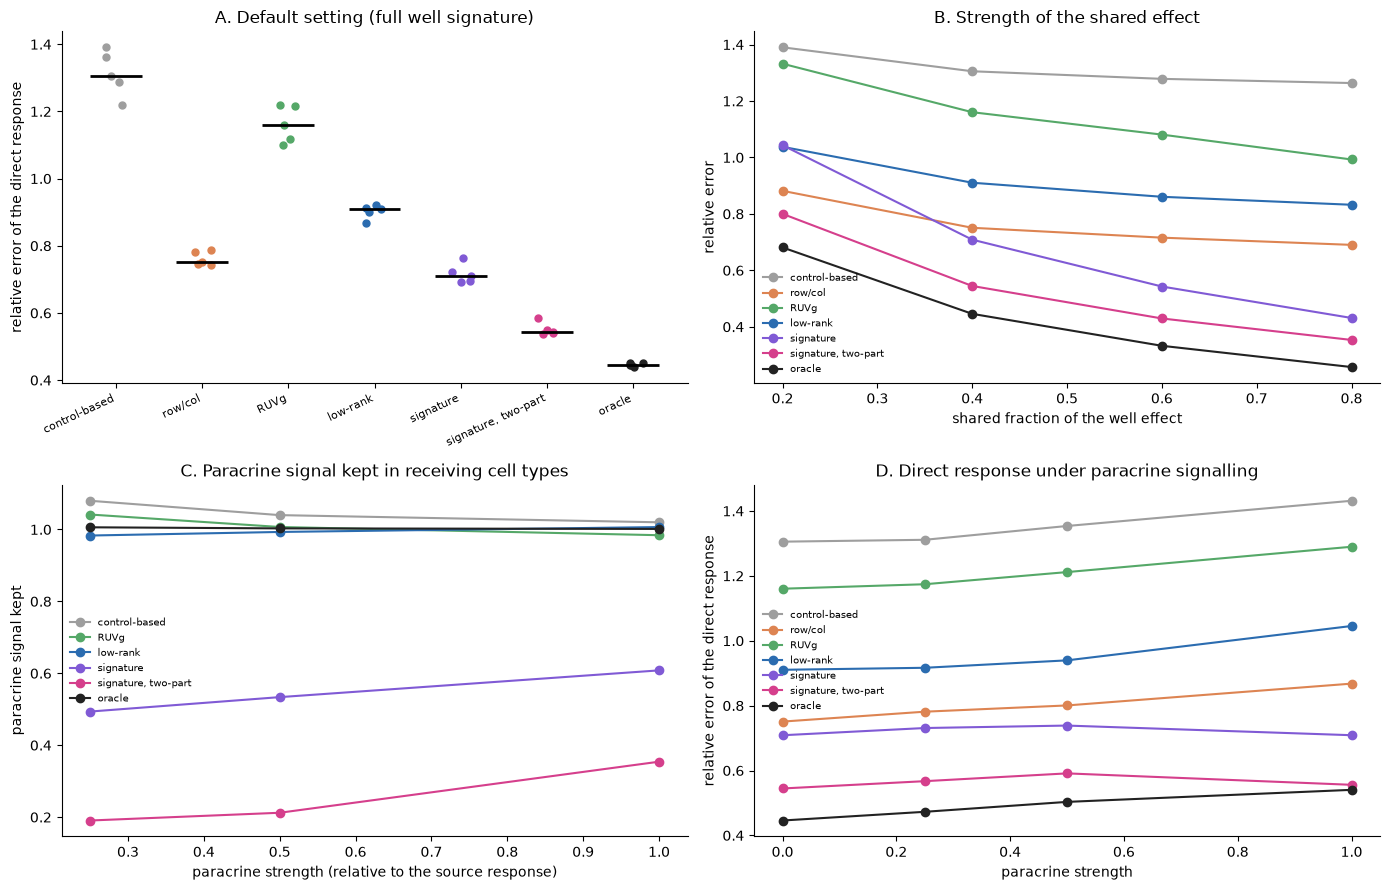

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_model_simulation_v2/aim2_model_simulation_v2.png True


In [12]:
COL_M = {"naive": "#9e9e9e", "row/col": "#dd8452", "RUVg": "#55a868", "low-rank": "#2b6cb0",
         "signature": "#805ad5", "signature, two-part": "#d53f8c", "oracle": "#222222"}
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
a = ax[0, 0]
d0 = res[res.sweep == "default"]
for i, m in enumerate(METHODS):
    v = d0[d0.method == m].rel_err.values
    a.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-.12, .12, len(v)), v, color=COL_M[m], s=25)
    a.hlines(np.median(v), i - .3, i + .3, color="k", lw=2)
a.set_xticks(range(len(METHODS))); a.set_xticklabels(METHODS, rotation=25, ha="right", fontsize=8)
a.set_ylabel("relative error of the direct response"); a.set_title("A. Default setting (full well signature)")

def sweep_plot(a, sweep, metric, xlabel, ylabel, title, methods=METHODS):
    sw = res[res.sweep == sweep]
    for m in methods:
        med = sw[sw.method == m].groupby("value")[metric].median()
        a.plot(med.index, med.values, "-o", color=COL_M[m], label=m)
    a.set_xlabel(xlabel); a.set_ylabel(ylabel); a.set_title(title); a.legend(frameon=False, fontsize=7)

sweep_plot(ax[0, 1], "shared_frac", "rel_err", "shared fraction of the well effect", "relative error", "B. Strength of the shared effect")
sweep_plot(ax[1, 0], "paracrine", "paracrine_kept", "paracrine strength (relative to the source response)",
           "paracrine signal kept", "C. Paracrine signal kept in receiving cell types",
           methods=["naive", "RUVg", "low-rank", "signature", "signature, two-part", "oracle"])
sweep_plot(ax[1, 1], "paracrine", "rel_err", "paracrine strength", "relative error of the direct response", "D. Direct response under paracrine signalling")
for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "aim2_model_simulation_v2.png"))
RENAME = {"naive": "control-based", "ours": "signature", "final": "signature",
          "final (v2)": "signature", "shared (ours)": "low-rank"}

def rename_labels(fig, mapping=RENAME):
    for a in fig.axes:
        a.set_xticklabels([mapping.get(t.get_text(), t.get_text()) for t in a.get_xticklabels()])
        leg = a.get_legend()
        if leg:
            for t in leg.get_texts():
                t.set_text(mapping.get(t.get_text(), t.get_text()))
        for t in a.texts:                       # point labels, e.g. in aim2_baselines.png
            t.set_text(mapping.get(t.get_text(), t.get_text()))

rename_labels(fig)
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf"))
plt.show()
print("Saved:", png, os.path.exists(png))

## 6. Tables

In [7]:
for sweep, metric in [("shared_frac", "rel_err"), ("shared_frac", "fpr"), ("paracrine", "rel_err"),
                      ("paracrine", "paracrine_kept"), ("composition", "rel_err"), ("composition", "fpr")]:
    t = res[res.sweep == sweep].groupby(["method", "value"])[metric].median().unstack().reindex(METHODS).round(3)
    print(f"{sweep} / {metric}"); print(t.to_string()); print()
summary.to_csv(os.path.join(OUT_DIR, "summary_default.csv"))
print(f"[whole notebook] {(time.time() - T_START) / 60:.1f} min")

shared_frac / rel_err
value                  0.2    0.4    0.6    0.8
method                                         
naive                1.390  1.305  1.278  1.264
row/col              0.882  0.751  0.716  0.690
RUVg                 1.332  1.160  1.081  0.993
low-rank             1.038  0.910  0.861  0.832
signature            1.043  0.709  0.543  0.431
signature, two-part  0.800  0.545  0.430  0.353
oracle               0.681  0.446  0.333  0.257

shared_frac / fpr
value                  0.2    0.4    0.6    0.8
method                                         
naive                0.765  0.786  0.802  0.893
row/col              0.072  0.099  0.087  0.082
RUVg                 0.742  0.747  0.657  0.672
low-rank             0.095  0.148  0.185  0.204
signature            0.616  0.690  0.710  0.757
signature, two-part  0.343  0.522  0.616  0.706
oracle               0.012  0.034  0.051  0.063

paracrine / rel_err
value                 0.00   0.25   0.50   1.00
method                    

## 7. How to read the results
* **A, B**: with a full well signature, how close does each method come to the oracle? The two-part signature should do best among the real methods when donors share the layout.
* **C**: the internal-control models remove paracrine signal by design (their estimand is the cell-autonomous response); methods that keep it also keep the technical well effect. This is a trade-off to report, not a bug.
* **D**: paracrine signal must not damage the estimate of the *direct* response of the responders.
* `fpr` stays high for all real methods in this simulator: an inert pair is called responsive whenever a small error repeats in every donor, and with 12 donors and 500 genes the test sees very small repeated errors. The oracle shows the floor of this test.

## 8. Calibrating the response test
The signature models call too many inert pairs responsive with the PBS-vs-PBS null (section 4): an error in the estimated signature of a position repeats in every donor, the PBS wells do not share it, and the t test across donors detects it. Two calibrated nulls:

* **Negative-control null**: the 95th percentile of the scores of half of the inert perturbations (in real data: half of the inert cytokines of Aim 1). The other half is used only to measure the false-call rate, so nothing is evaluated on the wells used for calibration.
* **Empirical null** (no labels needed): most (well, cell type) pairs do not respond, so the bulk of the log scores is the null. Threshold: median + 1.645 robust SD (MAD) of the log scores of all non-control pairs.

False calls are measured on the held-out half of the inert perturbations; true calls on the true responders.

In [8]:
from scipy.stats import norm

def thr_pbs(Y1, is_pbs, q=0.95):
    return calls(Y1, is_pbs, q)[1]

def thr_empirical(sc, mask, q=0.95):
    v = np.log(sc[mask & ~np.isnan(sc)])
    med = np.median(v); mad = 1.4826 * np.median(np.abs(v - med))
    return float(np.exp(med + norm.ppf(q) * mad))

def thr_negctrl(sc, idx, q=0.95):
    v = sc[idx].ravel(); v = v[~np.isnan(v)]
    return float(np.quantile(v, q))

CAL_METHODS = ["row/col", "low-rank", "signature", "signature, two-part", "oracle"]

def run_calibration(sim, seed):
    Y, is_pbs = sim["Y"], sim["is_pbs"]
    nr = discover_lowrank(Y, is_pbs)
    rng = np.random.default_rng(seed)
    inert = np.where(sim["inert"])[0]; rng.shuffle(inert)
    cal, ev = inert[: len(inert) // 2], inert[len(inert) // 2:]
    corrected = {"row/col": m_rowcol(Y), "low-rank": m_lowrank(Y, nr), "signature": m_signature(Y, nr)[0],
                 "signature, two-part": m_signature2(Y, nr)[0], "oracle": m_oracle(Y, sim["W"])}
    out = []
    for m, Y1 in corrected.items():
        sc = t_score(contrast(Y1, is_pbs))
        allp = np.broadcast_to((~is_pbs)[:, None], sc.shape)
        for null, thr in [("PBS-vs-PBS", thr_pbs(Y1, is_pbs)), ("negative controls", thr_negctrl(sc, cal)),
                          ("empirical", thr_empirical(sc, allp))]:
            fp = sc[ev][~np.isnan(sc[ev])] > thr
            tp = sc[sim["resp"]][~np.isnan(sc[sim["resp"]])] > thr
            out.append(dict(method=m, null=null, fpr=fp.mean(), tpr=tp.mean()))
    return out

CAL_CACHE = os.path.join(OUT_DIR, "calibration_results.csv")
if os.path.exists(CAL_CACHE):
    cal_res = pd.read_csv(CAL_CACHE); print("Loaded cache:", cal_res.shape)
else:
    jobs = [("default", 0.4, s) for s in SEEDS] + [("shared_frac", v, s) for v in SHARED_GRID for s in SEEDS]
    rows, t0 = [], time.time()
    for i, (sweep, val, seed) in enumerate(jobs, 1):
        for r in run_calibration(simulate2(seed, shared_frac=val), seed):
            rows.append(dict(sweep=sweep, value=val, seed=seed, **r))
        el = time.time() - t0
        print(f"  {i}/{len(jobs)} runs | elapsed {el / 60:.1f} min | remaining ~{el / i * (len(jobs) - i) / 60:.1f} min", flush=True)
    cal_res = pd.DataFrame(rows); cal_res.to_csv(CAL_CACHE, index=False); print("Saved:", CAL_CACHE)
tab = (cal_res[cal_res.sweep == "default"].groupby(["method", "null"])[["fpr", "tpr"]].median()
       .unstack("null").reindex(CAL_METHODS).round(3))
print(tab.to_string())

Loaded cache: (375, 7)
                           fpr                                    tpr                            
null                PBS-vs-PBS empirical negative controls PBS-vs-PBS empirical negative controls
method                                                                                           
row/col                  0.133       0.0             0.065      0.922     0.566             0.904
low-rank                 0.133       0.0             0.046      0.880     0.527             0.860
signature                0.711       0.0             0.056      1.000     0.726             0.962
signature, two-part      0.411       0.0             0.044      1.000     0.984             1.000
oracle                   0.026       0.0             0.037      1.000     1.000             1.000


/tmp/ipykernel_538645/2159150347.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  a.set_xticklabels([mapping.get(t.get_text(), t.get_text()) for t in a.get_xticklabels()])
/tmp/ipykernel_538645/2159150347.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  a.set_xticklabels([mapping.get(t.get_text(), t.get_text()) for t in a.get_xticklabels()])


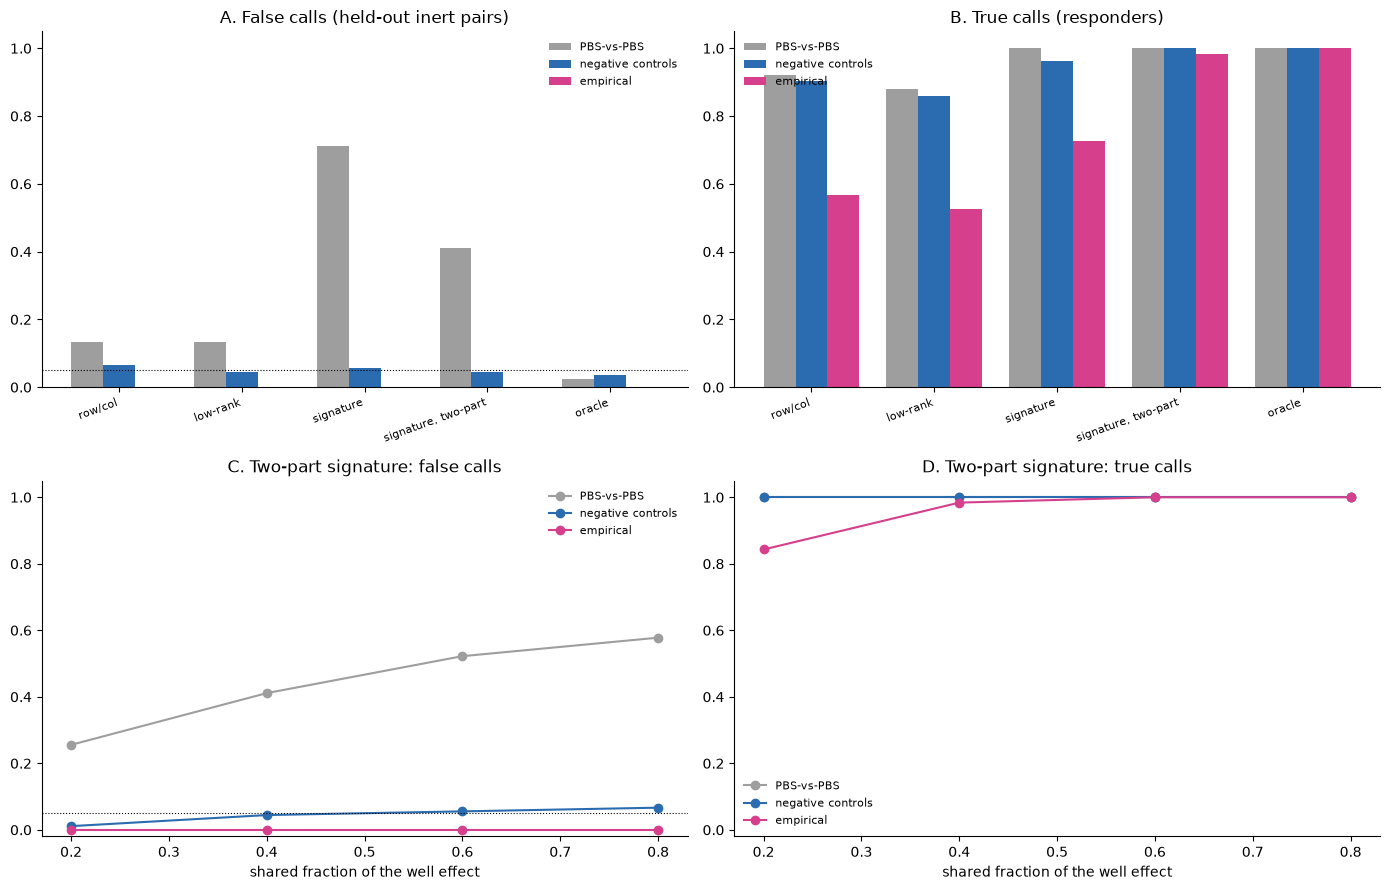

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_model_simulation_v2/aim2_calibration.png True
[whole notebook] 266.5 min


In [13]:
NULLS = ["PBS-vs-PBS", "negative controls", "empirical"]
NCOL = {"PBS-vs-PBS": "#9e9e9e", "negative controls": "#2b6cb0", "empirical": "#d53f8c"}
d0 = cal_res[cal_res.sweep == "default"]
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
x = np.arange(len(CAL_METHODS)); w = 0.26
for j, (metric, title) in enumerate([("fpr", "A. False calls (held-out inert pairs)"), ("tpr", "B. True calls (responders)")]):
    a = ax[0, j]
    for i, nl in enumerate(NULLS):
        med = d0[d0.null == nl].groupby("method")[metric].median().reindex(CAL_METHODS)
        a.bar(x + (i - 1) * w, med.values, w, color=NCOL[nl], label=nl)
    if metric == "fpr":
        a.axhline(0.05, color="k", ls=":", lw=.8)
    a.set_xticks(x); a.set_xticklabels(CAL_METHODS, rotation=20, ha="right", fontsize=8)
    a.set_ylim(0, 1.05); a.set_title(title); a.legend(frameon=False, fontsize=8)
sw = cal_res[(cal_res.sweep == "shared_frac") & (cal_res.method == "signature, two-part")]
for j, (metric, title) in enumerate([("fpr", "C. Two-part signature: false calls"), ("tpr", "D. Two-part signature: true calls")]):
    a = ax[1, j]
    for nl in NULLS:
        med = sw[sw.null == nl].groupby("value")[metric].median()
        a.plot(med.index, med.values, "-o", color=NCOL[nl], label=nl)
    if metric == "fpr":
        a.axhline(0.05, color="k", ls=":", lw=.8)
    a.set_xlabel("shared fraction of the well effect"); a.set_ylim(-0.02, 1.05); a.set_title(title); a.legend(frameon=False, fontsize=8)
for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "aim2_calibration.png"))
RENAME = {"naive": "control-based", "ours": "signature", "final": "signature",
          "final (v2)": "signature", "shared (ours)": "low-rank"}

def rename_labels(fig, mapping=RENAME):
    for a in fig.axes:
        a.set_xticklabels([mapping.get(t.get_text(), t.get_text()) for t in a.get_xticklabels()])
        leg = a.get_legend()
        if leg:
            for t in leg.get_texts():
                t.set_text(mapping.get(t.get_text(), t.get_text()))
        for t in a.texts:                       # point labels, e.g. in aim2_baselines.png
            t.set_text(mapping.get(t.get_text(), t.get_text()))

rename_labels(fig)
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf"))
plt.show()
print("Saved:", png, os.path.exists(png))
print(f"[whole notebook] {(time.time() - T_START) / 60:.1f} min")

  10/60 runs | elapsed 0.5 min | remaining ~2.4 min
  20/60 runs | elapsed 1.0 min | remaining ~1.9 min
  30/60 runs | elapsed 1.5 min | remaining ~1.5 min
  40/60 runs | elapsed 2.0 min | remaining ~1.0 min
  50/60 runs | elapsed 2.6 min | remaining ~0.5 min
  60/60 runs | elapsed 3.1 min | remaining ~0.0 min
Saved: results/cache/aim2_model_simulation_v2/sim_v3_misspecified.csv
Relative error of the direct response (median over seeds):
method                  naive  row/col   RUVg  low-rank  signature  signature, two-part  well mean  oracle
kind          strength                                                                                    
cell-specific 0.00      1.305    0.751  1.160     0.910      0.709                0.545      0.804   0.446
              0.25      1.334    0.786  1.196     0.905      0.839                0.725      0.956   0.467
              0.50      1.333    0.788  1.213     0.918      1.146                1.056      1.237   0.467
count-scale   0.00      

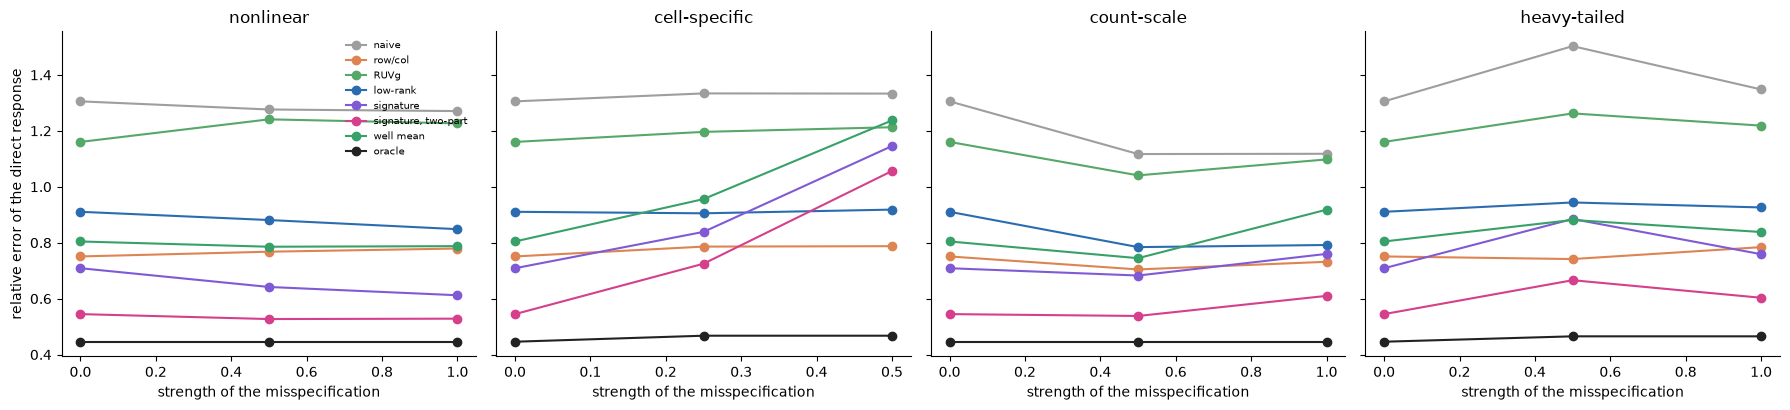

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_model_simulation_v2/simulation_v3_misspecified.png
[misspecified simulator] 3.3 min


In [10]:
# ===================== aim2_model_simulation_v2.ipynb, new section 9 (after cell 17) =====================
# 9. Third simulator: well effects that the model does not assume.
# The second simulator generates the technical effect as b_c * s_dk (one signature per well, one slope per cell type
# and gene), the same form the signature model fits, so part of its advantage may come from that match. Here the
# effect breaks this form in four ways, each at three strengths (0 = the second simulator):
#   nonlinear      : W = b * (s + g * (s^2 - mean s^2))          the signature enters non-linearly
#   cell-specific  : W_c = b_c * ((1 - g) s + g s_c)              each cell type sees partly its own signature
#                    (s_c is s with its genes permuted for that cell type, so it has the same size and no overlap)
#   count-scale    : on the count scale, a background that is shared by the well is added to every cell type:
#                    Y = log(exp(mu + tau) + g * exp(s_well)) ; its effect on log expression depends on the
#                    expression level (large for lowly expressed genes, small for highly expressed ones)
#   heavy-tailed   : the well signature has t-distributed entries (3 degrees of freedom), scaled to the same SD,
#                    mixed with the Gaussian one in proportion g
# The oracle removes the true technical part, computed as the difference between the data with and without it.
# The plain well mean (all other cell types, slope one) is added as a method.
# Fixed before running: the conclusion "the two-part signature has the lowest error among the real methods" holds
# under misspecification if it is lowest in every kind at the middle strength; and the gap between the signature
# models and the oracle is reported for every kind and strength.
t0 = time.time()
MIS_KINDS = ["nonlinear", "cell-specific", "count-scale", "heavy-tailed"]
MIS_GRID = {"nonlinear": [0.0, 0.5, 1.0], "cell-specific": [0.0, 0.25, 0.5],
            "count-scale": [0.0, 0.5, 1.0], "heavy-tailed": [0.0, 0.5, 1.0]}


def simulate3(seed=0, kind="nonlinear", g=0.5, D=12, C=6, G=500, p_resp=0.3, frac_inert=0.15, shared_frac=0.4,
              well_sd=0.25, noise_sd=0.15, resp_size=0.5, resp_gene_frac=0.2, row_h=1.0):
    rng = np.random.default_rng(seed)
    K = len(WELLS)
    is_pbs = np.isin(WELLS, PBS)
    row_eff = rng.normal(0, 0.5, (8, G)); row_eff[7] += row_h * rng.normal(0, 1, G)
    col_eff = rng.normal(0, 0.3, (12, G))
    well_part = rng.normal(0, 0.7, (K, G))
    don_part = rng.normal(0, 0.7, (D, K, G))
    if kind == "heavy-tailed" and g > 0:
        t3 = lambda size: rng.standard_t(3, size) * 0.7 / np.sqrt(3.0)          # same SD as N(0, 0.7)
        well_part = (1 - g) * well_part + g * t3((K, G))
        don_part = (1 - g) * don_part + g * t3((D, K, G))
    s = (row_eff[ROW] + col_eff[COL] + well_part)[None] + don_part           # [D, K, G]
    s = s / s.std()
    b = rng.uniform(0.5, 1.5, (C, 1)) * (1 + 0.3 * rng.normal(0, 1, (C, G)))
    if kind == "nonlinear" and g > 0:
        s_eff = np.broadcast_to((s + g * (s ** 2 - (s ** 2).mean()))[:, :, None, :], (D, K, C, G))
    elif kind == "cell-specific" and g > 0:
        s_eff = np.empty((D, K, C, G))
        for c in range(C):
            perm = rng.permutation(G)
            s_eff[:, :, c] = (1 - g) * s + g * s[..., perm]
    else:
        s_eff = np.broadcast_to(s[:, :, None, :], (D, K, C, G))
    W = s_eff * b[None, None]
    W = W * (well_sd / W.std())
    W_un = rng.normal(0, well_sd * np.sqrt((1 - shared_frac) / shared_frac), (D, K, C, G))
    resp = np.zeros((K, C), bool)
    active = (~is_pbs) & (rng.random(K) > frac_inert)
    resp[active] = rng.random((active.sum(), C)) < p_resp
    tau = np.zeros((K, C, G))
    for k in np.where(resp.any(1))[0]:
        prog = (rng.random(G) < resp_gene_frac) * rng.normal(0, 1, G)
        for c in np.where(resp[k])[0]:
            tau[k, c] = resp_size * rng.uniform(0.5, 1.5) * prog * (1 + 0.3 * rng.normal(0, 1, G))
    mu = rng.normal(0, 1, (1, 1, C, G)) + rng.normal(0, 0.3, (D, 1, C, G))
    eps = rng.normal(0, noise_sd, (D, K, C, G))
    clean = mu + tau[None] + eps
    if kind == "count-scale" and g > 0:
        # background shared by the well, added on the count scale; its size is set so that the mean absolute
        # change it makes equals that of the multiplicative effect W at g = 1
        bg = np.exp(s[:, :, None, :] * 1.0 + rng.normal(0, 0.3, (1, 1, C, G)))
        with_bg = lambda a: np.log(np.exp(clean) + a * bg)
        lo, hi = 1e-4, 10.0
        target = np.abs(W).mean()
        for _ in range(40):                                                # bisection on the background amount
            mid = np.sqrt(lo * hi)
            if np.abs(with_bg(mid) - clean).mean() < target:
                lo = mid
            else:
                hi = mid
        tech = g * (with_bg(mid) - clean) + (1 - g) * W
    else:
        tech = W
    Y = clean + tech + W_un
    return dict(Y=Y.astype(np.float32), W=tech.astype(np.float32), tau=tau, tau_total=tau, resp=resp,
                recv=np.zeros_like(resp), is_pbs=is_pbs, inert=(~is_pbs) & ~resp.any(1))


def m_wellmean(Y, **kw):
    """Well mean: each cell type minus the leave-one-out mean of all other cell types of the well (slope one)."""
    D, K, C, G = Y.shape
    Y0 = center_on(Y, np.ones((D, K, C), bool))
    S = Y0.sum(2, keepdims=True)
    return Y0 - (S - Y0) / (C - 1)


METHODS3 = METHODS[:-1] + ["well mean", "oracle"]
COL_M["well mean"] = "#38a169"


def run_all3(sim):
    out = run_all(sim)
    out["well mean"] = evaluate(m_wellmean(sim["Y"]), sim)
    return out


CACHE3 = os.path.join(OUT_DIR, "sim_v3_misspecified.csv")
if os.path.exists(CACHE3):
    res3 = pd.read_csv(CACHE3); print("Loaded cache:", res3.shape)
else:
    jobs = [(kd, g, s) for kd in MIS_KINDS for g in MIS_GRID[kd] for s in SEEDS]
    rows = []
    for i, (kd, g, sd) in enumerate(jobs, 1):
        out = run_all3(simulate3(sd, kind=kd, g=g))
        for m in METHODS3:
            rows.append(dict(kind=kd, strength=g, seed=sd, method=m, **out[m]))
        if i % 10 == 0 or i == len(jobs):
            el = time.time() - t0
            print(f"  {i}/{len(jobs)} runs | elapsed {el / 60:.1f} min | remaining ~{el / i * (len(jobs) - i) / 60:.1f} min", flush=True)
    res3 = pd.DataFrame(rows); res3.to_csv(CACHE3, index=False); print("Saved:", CACHE3)

TAB3 = res3.groupby(["kind", "strength", "method"]).rel_err.median().unstack("method")[METHODS3]
TAB3.to_csv(os.path.join(OUT_DIR, "sim_v3_rel_err.csv"))
print("Relative error of the direct response (median over seeds):")
print(TAB3.round(3).to_string())
FPR3 = res3.groupby(["kind", "strength", "method"]).fpr.median().unstack("method")[METHODS3]
print("\nFalse calls (PBS-vs-PBS null, all non-responding pairs):")
print(FPR3.round(3).to_string())

real = [m for m in METHODS3 if m != "oracle"]
mid = {kd: MIS_GRID[kd][1] for kd in MIS_KINDS}
best = {kd: TAB3.loc[(kd, mid[kd]), real].idxmin() for kd in MIS_KINDS}
print("\nLowest error among real methods at the middle strength:", best)
print("Fixed rule (two-part lowest in every kind at the middle strength):",
      all(v == "signature, two-part" for v in best.values()))
gap = (TAB3["signature, two-part"] - TAB3["oracle"]).unstack("strength")
print("\nGap two-part minus oracle, by kind and strength:"); print(gap.round(3).to_string())

fig, ax = plt.subplots(1, len(MIS_KINDS), figsize=(18, 4.2), sharey=True)
for a, kd in zip(ax, MIS_KINDS):
    for m in METHODS3:
        v = TAB3.loc[kd, m]
        a.plot(v.index, v.values, "-o", color=COL_M[m], label=m)
    a.set_title(kd); a.set_xlabel("strength of the misspecification")
    a.spines[["top", "right"]].set_visible(False)
ax[0].set_ylabel("relative error of the direct response"); ax[0].legend(frameon=False, fontsize=7)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "simulation_v3_misspecified.png"))
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf")); plt.show()
print("Saved:", png)
print(f"[misspecified simulator] {(time.time() - t0) / 60:.1f} min")

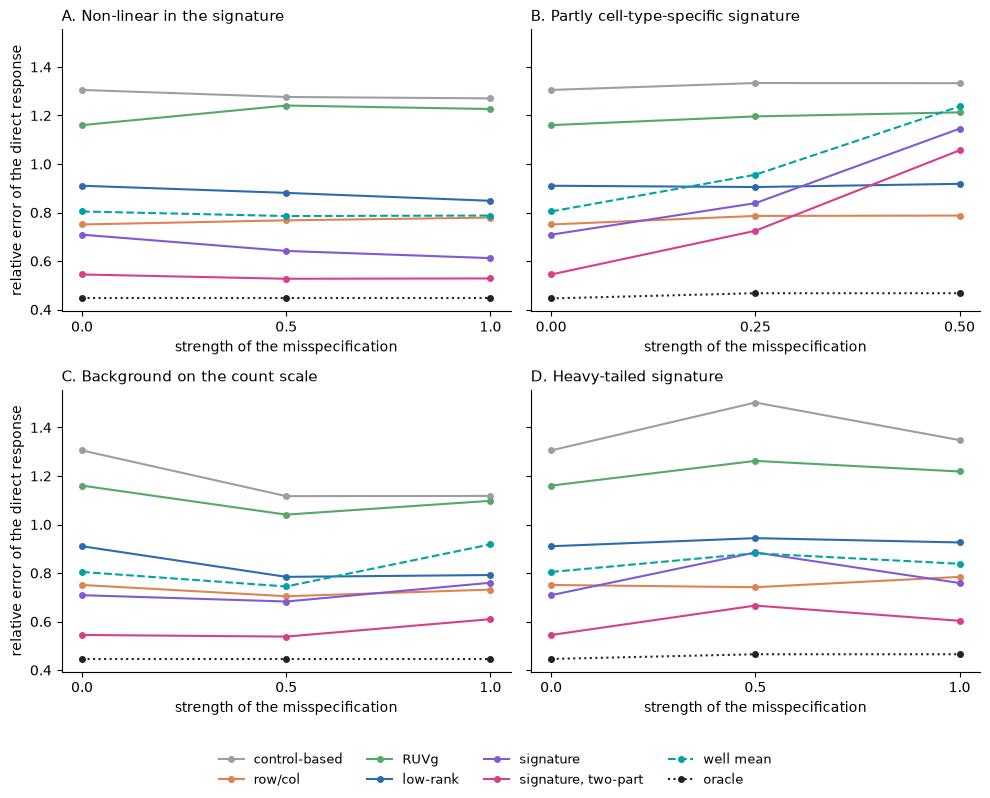

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_model_simulation_v2/simulation_v3_misspecified.png


In [15]:
# Figure for the paper: third simulator as a 2 x 2 panel (run after section 9; uses res3, TAB3, METHODS3, MIS_KINDS).
# Distinct colours for RUVg and the well mean, the well mean dashed; one shared legend below the panels.
COL_FIG = {"naive": "#9e9e9e", "row/col": "#dd8452", "RUVg": "#55a868", "low-rank": "#2b6cb0",
           "signature": "#805ad5", "signature, two-part": "#d53f8c", "well mean": "#00a3a3", "oracle": "#222222"}
STYLE = {"well mean": "--", "oracle": ":"}
TITLES = {"nonlinear": "A. Non-linear in the signature", "cell-specific": "B. Partly cell-type-specific signature",
          "count-scale": "C. Background on the count scale", "heavy-tailed": "D. Heavy-tailed signature"}
fig, ax = plt.subplots(2, 2, figsize=(10, 8), sharey=True)
for a, kd in zip(ax.ravel(), MIS_KINDS):
    for m in METHODS3:
        v = TAB3.loc[kd, m]
        a.plot(v.index, v.values, STYLE.get(m, "-"), marker="o", ms=4, color=COL_FIG[m], label=m, lw=1.5)
    a.set_title(TITLES[kd], loc="left", fontsize=11)
    a.set_xlabel("strength of the misspecification")
    a.set_xticks(MIS_GRID[kd])
    a.spines[["top", "right"]].set_visible(False)
for a in ax[:, 0]:
    a.set_ylabel("relative error of the direct response")
h, l = ax[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.08, 1, 1))
png = os.path.abspath(os.path.join(OUT_DIR, "simulation_v3_misspecified.png"))
RENAME = {"naive": "control-based", "ours": "signature", "final": "signature",
          "final (v2)": "signature", "shared (ours)": "low-rank", "two-part": "signature, two-part"}

def rename_labels(fig, mapping=RENAME):
    sub = lambda s: mapping.get(s, s)
    legends = list(fig.legends) + [a.get_legend() for a in fig.axes if a.get_legend()]
    for leg in legends:
        for t in leg.get_texts():
            t.set_text(sub(t.get_text()))
    for a in fig.axes:
        a.set_xticklabels([sub(t.get_text()) for t in a.get_xticklabels()])
        for t in a.texts:
            t.set_text(sub(t.get_text()))
        a.set_ylabel(a.get_ylabel().replace("naive", "control-based"))

rename_labels(fig)
fig.savefig(png, dpi=300); fig.savefig(png.replace(".png", ".pdf")); plt.show()
print("Saved:", png)